In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import resample
from sklearn.model_selection import train_test_split, GridSearchCV,cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score
import pickle

Data Collection and Processing

In [4]:
data=pd.read_csv('/content/Rainfall.csv')

In [5]:
data.shape

(366, 12)

In [6]:
data.head()

,day,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,windspeed
0,1,1025.9,19.9,18.3,16.8,13.1,72,49,yes,9.3,80.0,26.3
1,2,1022.0,21.7,18.9,17.2,15.6,81,83,yes,0.6,50.0,15.3
2,3,1019.7,20.3,19.3,18.0,18.4,95,91,yes,0.0,40.0,14.2
3,4,1018.9,22.3,20.6,19.1,18.8,90,88,yes,1.0,50.0,16.9
4,5,1015.9,21.3,20.7,20.2,19.9,95,81,yes,0.0,40.0,13.7


In [7]:
data.tail()

,day,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,windspeed
361,27,1022.7,18.8,17.7,16.9,15.0,84,90,yes,0.0,30.0,18.4
362,28,1026.6,18.6,17.3,16.3,12.8,75,85,yes,1.0,20.0,25.9
363,29,1025.9,18.9,17.7,16.4,13.3,75,78,yes,4.6,70.0,33.4
364,30,1025.3,19.2,17.3,15.2,13.3,78,86,yes,1.2,20.0,20.9
365,31,1026.4,20.5,17.8,15.5,13.0,74,66,no,5.7,20.0,23.3


In [8]:
data['day'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])

In [9]:
print('Data info')
data.info()

Data info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   day                     366 non-null    int64  
 1   pressure                366 non-null    float64
 2   maxtemp                 366 non-null    float64
 3   temparature             366 non-null    float64
 4   mintemp                 366 non-null    float64
 5   dewpoint                366 non-null    float64
 6   humidity                366 non-null    int64  
 7   cloud                   366 non-null    int64  
 8   rainfall                366 non-null    object 
 9   sunshine                366 non-null    float64
 10           winddirection  365 non-null    float64
 11  windspeed               365 non-null    float64
dtypes: float64(8), int64(3), object(1)
memory usage: 34.4+ KB


In [10]:
#remove extra spaces in all columns
data.columns=data.columns.str.strip()

In [11]:
data.columns

Index(['day', 'pressure', 'maxtemp', 'temparature', 'mintemp', 'dewpoint',
       'humidity', 'cloud', 'rainfall', 'sunshine', 'winddirection',
       'windspeed'],
      dtype='object')

In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   day            366 non-null    int64  
 1   pressure       366 non-null    float64
 2   maxtemp        366 non-null    float64
 3   temparature    366 non-null    float64
 4   mintemp        366 non-null    float64
 5   dewpoint       366 non-null    float64
 6   humidity       366 non-null    int64  
 7   cloud          366 non-null    int64  
 8   rainfall       366 non-null    object 
 9   sunshine       366 non-null    float64
 10  winddirection  365 non-null    float64
 11  windspeed      365 non-null    float64
dtypes: float64(8), int64(3), object(1)
memory usage: 34.4+ KB


In [13]:
data=data.drop(columns=['day'])

In [15]:
data.head()

,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,windspeed
0,1025.9,19.9,18.3,16.8,13.1,72,49,yes,9.3,80.0,26.3
1,1022.0,21.7,18.9,17.2,15.6,81,83,yes,0.6,50.0,15.3
2,1019.7,20.3,19.3,18.0,18.4,95,91,yes,0.0,40.0,14.2
3,1018.9,22.3,20.6,19.1,18.8,90,88,yes,1.0,50.0,16.9
4,1015.9,21.3,20.7,20.2,19.9,95,81,yes,0.0,40.0,13.7


In [16]:
data.isnull().sum()

,0
pressure,0
maxtemp,0
temparature,0
mintemp,0
dewpoint,0
humidity,0
cloud,0
rainfall,0
sunshine,0
winddirection,1


In [17]:
data['winddirection'].unique()

array([ 80.,  50.,  40.,  20.,  30.,  60.,  70.,  10., 200., 220., 120.,
       190., 210., 300., 240., 180., 230.,  90., 170., 150., 100., 130.,
        nan, 160., 270., 280., 250., 260., 290., 350., 110., 140.])

In [18]:
#handle missing values
data['winddirection']=data['winddirection'].fillna(data['winddirection']).mode()[0]
data['windspeed']=data['windspeed'].fillna(data['windspeed']).median()

In [19]:
data.isnull().sum()

,0
pressure,0
maxtemp,0
temparature,0
mintemp,0
dewpoint,0
humidity,0
cloud,0
rainfall,0
sunshine,0
winddirection,0


In [25]:
data['rainfall'].unique()

array([nan])

In [28]:
#converting the yes and no to 1 and 0 respectively
data['rainfall']=data['rainfall'].map({'yes':1,'no':0})

In [29]:
# Reload the original rainfall column to inspect what went wrong
temp_df = pd.read_csv('/content/Rainfall.csv')
# Strip whitespaces from column names in temp_df
temp_df.columns = temp_df.columns.str.strip()

print("Original unique values in rainfall:", temp_df['rainfall'].unique())

# Let's clean whitespaces from the rainfall column and check again
if temp_df['rainfall'].dtype == 'object':
    temp_df['rainfall'] = temp_df['rainfall'].str.strip().str.lower()
    print("Cleaned unique values in rainfall:", temp_df['rainfall'].unique())

# Now try mapping on the cleaned column
data['rainfall'] = temp_df['rainfall'].map({'yes': 1, 'no': 0})
print("\nMapped values in data['rainfall']:", data['rainfall'].unique())
data.head()

Original unique values in rainfall: ['yes' 'no']
Cleaned unique values in rainfall: ['yes' 'no']

Mapped values in data['rainfall']: [1 0]


,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,windspeed
0,1025.9,19.9,18.3,16.8,13.1,72,49,1,9.3,20.0,20.5
1,1022.0,21.7,18.9,17.2,15.6,81,83,1,0.6,20.0,20.5
2,1019.7,20.3,19.3,18.0,18.4,95,91,1,0.0,20.0,20.5
3,1018.9,22.3,20.6,19.1,18.8,90,88,1,1.0,20.0,20.5
4,1015.9,21.3,20.7,20.2,19.9,95,81,1,0.0,20.0,20.5


Exploratory Data Analysis

In [30]:
data.shape

(366, 11)

In [31]:
#for setting plot style for all the plots
sns.set(style='whitegrid')

In [32]:
data.describe()

,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,windspeed
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.0,366.0
mean,1013.742623,26.191257,23.747268,21.894536,19.989071,80.177596,71.128415,0.680328,4.419399,20.0,20.5
std,6.414776,5.978343,5.632813,5.594153,5.997021,10.062470,21.798012,0.466988,3.934398,0.0,0.0
min,998.500000,7.100000,4.900000,3.100000,-0.400000,36.000000,0.000000,0.000000,0.000000,20.0,20.5
25%,1008.500000,21.200000,18.825000,17.125000,16.125000,75.000000,58.000000,0.000000,0.500000,20.0,20.5
50%,1013.000000,27.750000,25.450000,23.700000,21.950000,80.500000,80.000000,1.000000,3.500000,20.0,20.5
75%,1018.100000,31.200000,28.600000,26.575000,25.000000,87.000000,88.000000,1.000000,8.200000,20.0,20.5
max,1034.600000,36.300000,32.400000,30.000000,26.700000,98.000000,100.000000,1.000000,12.100000,20.0,20.5


In [33]:
data.columns

Index(['pressure', 'maxtemp', 'temparature', 'mintemp', 'dewpoint', 'humidity',
       'cloud', 'rainfall', 'sunshine', 'winddirection', 'windspeed'],
      dtype='object')

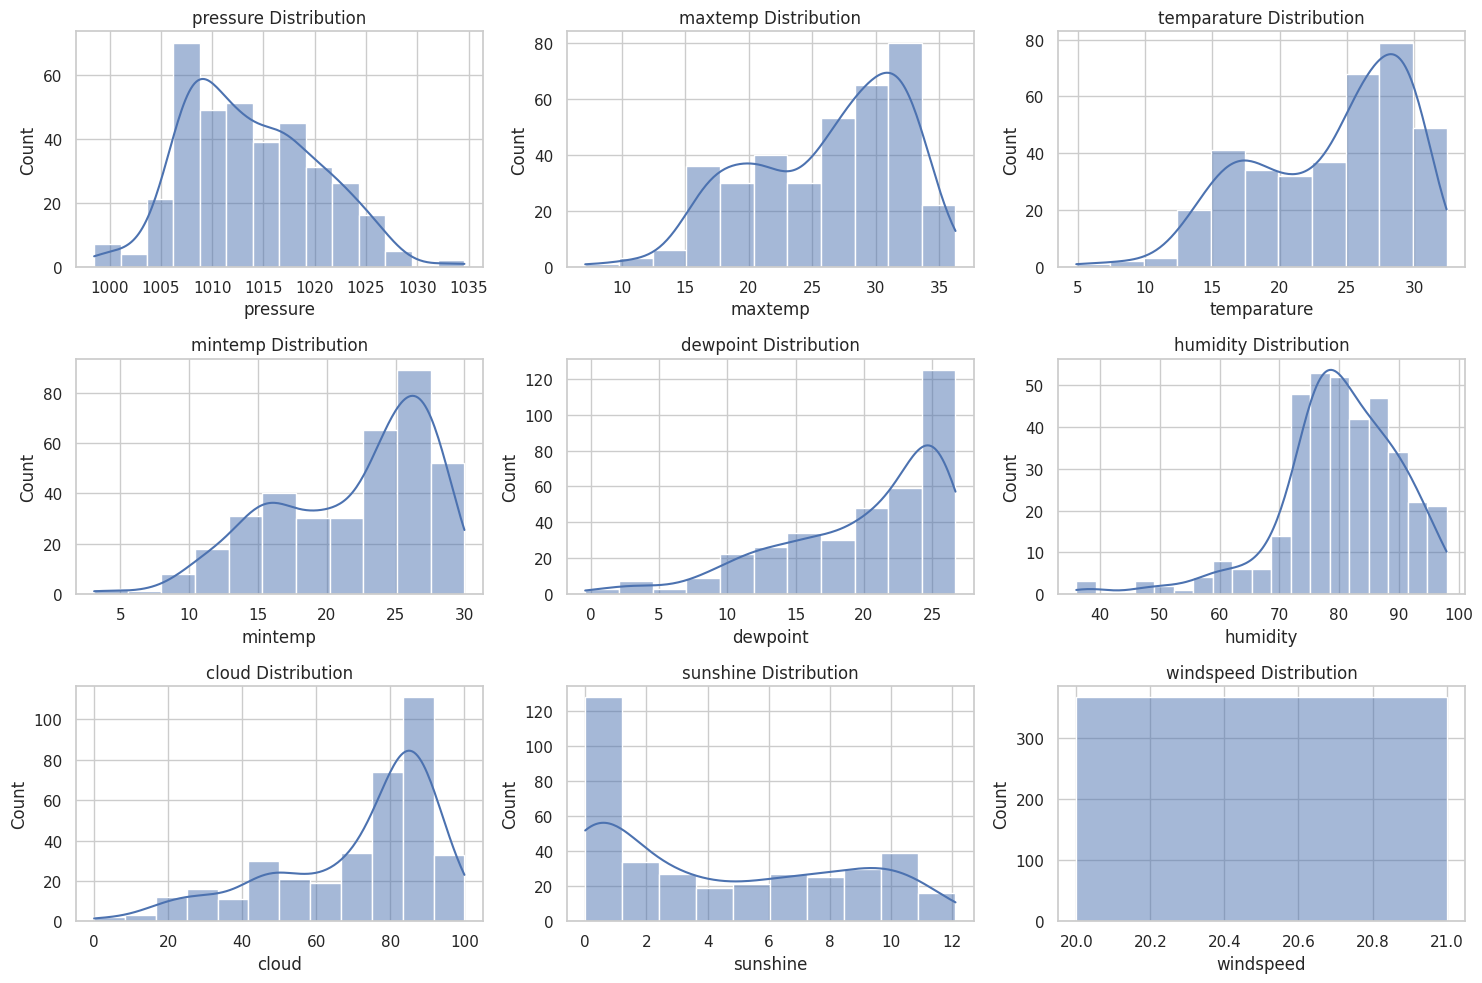

In [38]:
plt.figure(figsize=(15,10))
for i, column in enumerate(['pressure', 'maxtemp', 'temparature', 'mintemp', 'dewpoint', 'humidity',
       'cloud', 'sunshine', 'windspeed'], 1):
    plt.subplot(3,3,i)
    sns.histplot(data[column], kde=True)
    plt.title(f'{column} Distribution')

plt.tight_layout()
plt.show()

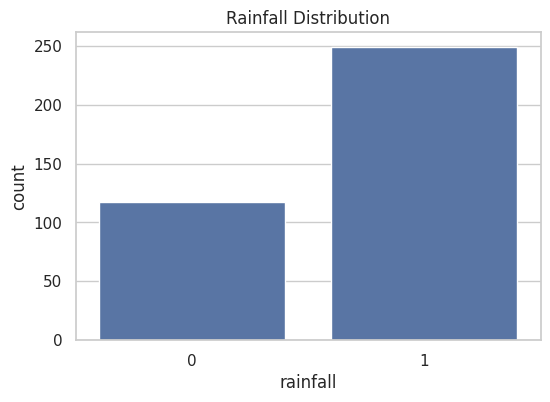

In [39]:
plt.figure(figsize=(6,4))
sns.countplot(x='rainfall', data=data)
plt.title('Rainfall Distribution')
plt.show()

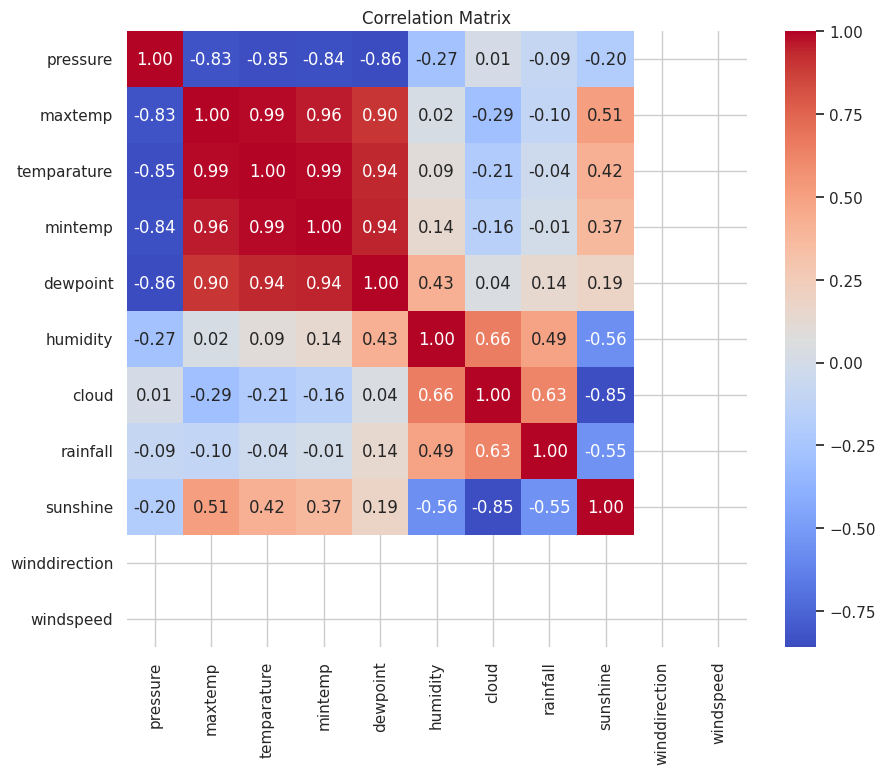

In [40]:
#correlation matrix
plt.figure(figsize=(10,8))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm',fmt='.2f')
plt.title('Correlation Matrix')
plt.show()
#

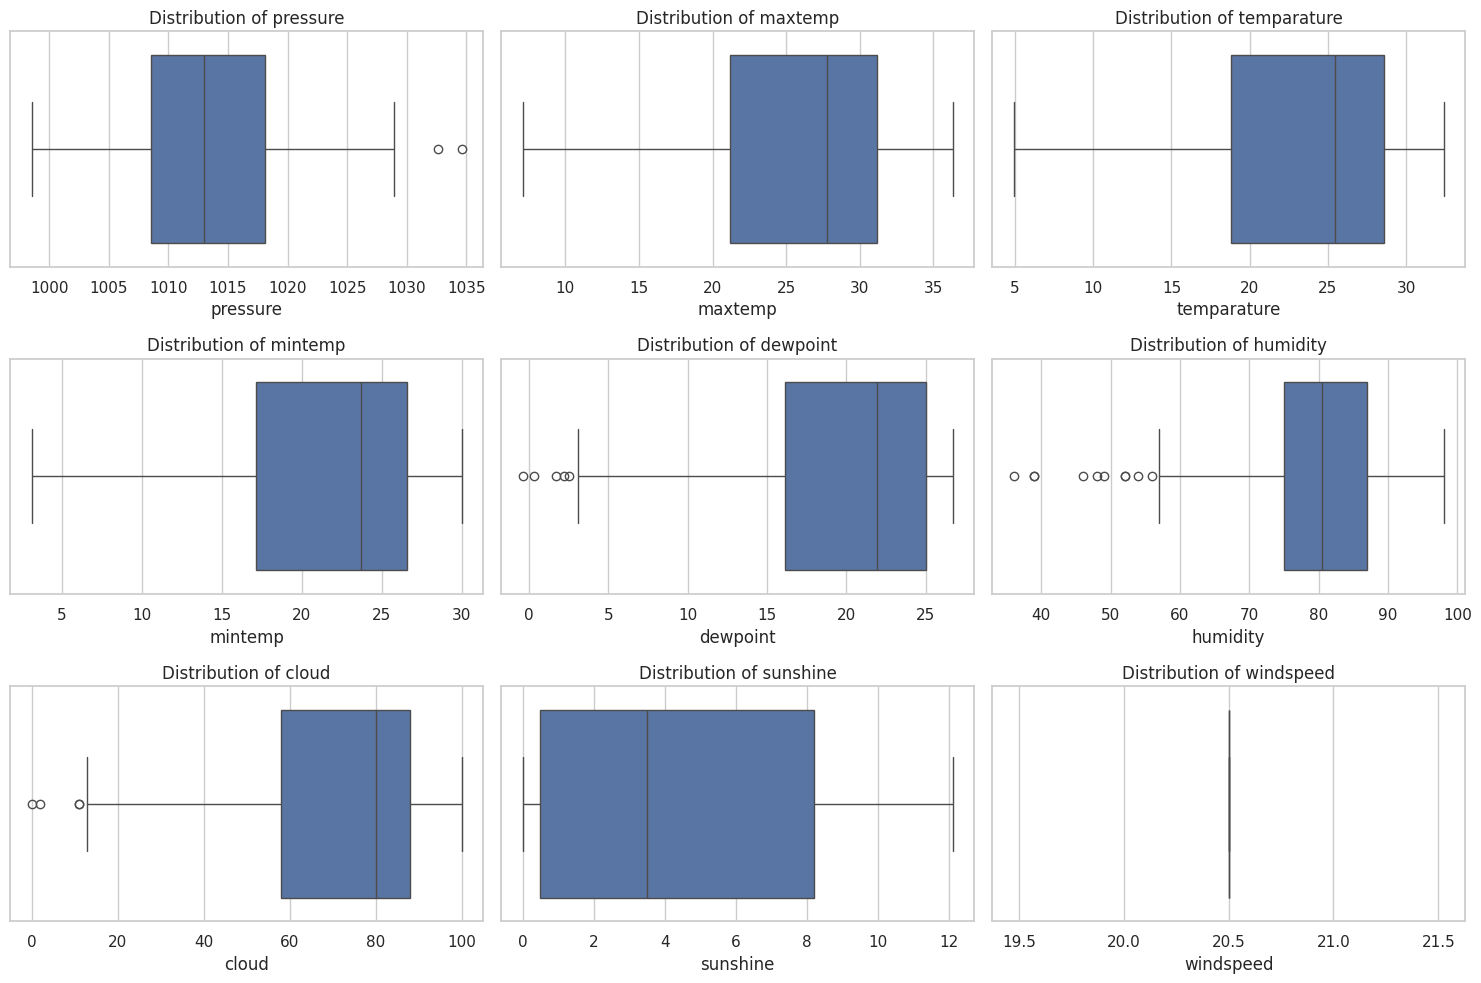

In [42]:
#boxplot distribution
plt.figure(figsize=(15,10))
for i, column in enumerate(['pressure', 'maxtemp', 'temparature', 'mintemp', 'dewpoint', 'humidity',
       'cloud', 'sunshine', 'windspeed'], 1):
    plt.subplot(3,3,i)
    sns.boxplot(x=data[column])
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

Data Prepocessing


In [44]:
#drop highly correlated column
data=data.drop(columns=['maxtemp', 'temparature', 'mintemp'])

In [45]:
data.head()

,pressure,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,windspeed
0,1025.9,13.1,72,49,1,9.3,20.0,20.5
1,1022.0,15.6,81,83,1,0.6,20.0,20.5
2,1019.7,18.4,95,91,1,0.0,20.0,20.5
3,1018.9,18.8,90,88,1,1.0,20.0,20.5
4,1015.9,19.9,95,81,1,0.0,20.0,20.5


In [46]:
print(data['rainfall'].value_counts())

rainfall
1    249
0    117
Name: count, dtype: int64


In [47]:
# separate majority and minority class
df_majority = data[data['rainfall']==1]
df_minority = data[data['rainfall']==0]

# upsample minority class
df_minority_upsampled = resample(df_minority,
                                 replace=True,)

In [48]:
print(df_majority.shape)
print(df_minority_upsampled.shape)

(249, 8)
(117, 8)


In [49]:
#downsampe  mjority class to match minority count
df_majority_downsampled = resample(df_majority,
                                 replace=False,n_samples=len(df_minority_upsampled),random_state=42)

In [50]:
df_majority.shape

(249, 8)

In [51]:
df_majority_downsampled.shape

(117, 8)

In [52]:
df_downsampled=pd.concat([df_majority_downsampled,df_minority_upsampled])

In [53]:
df_downsampled.shape

(234, 8)

In [54]:
#shuffle the final dataframe
df_downsampled=df_downsampled.sample(frac=1,random_state=42).reset_index(drop=True)

In [55]:
df_downsampled.head()

,pressure,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,windspeed
0,1022.2,14.1,78,90,1,0.0,20.0,20.5
1,1008.6,20.6,75,62,0,8.8,20.0,20.5
2,1003.4,24.9,72,40,0,10.0,20.0,20.5
3,1007.6,24.8,85,84,1,1.8,20.0,20.5
4,1018.1,16.9,82,71,0,3.0,20.0,20.5


In [56]:
df_downsampled['rainfall'].value_counts()

,count
rainfall,
1,117
0,117


In [57]:
from re import X
#split features and targets
X=df_downsampled.drop(columns=['rainfall'])
y=df_downsampled['rainfall']

In [58]:
#splitting the data into training data and test data
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)




Model Training

In [60]:
rf_model=RandomForestClassifier(random_state=42)
param_grid_rf={
    'n_estimators':[50,100,200],
    'max_features':['sqrt','log2'],
    'max_depth':[None,10,20,30],
    'min_samples_split':[2,5,10],
    'min_samples_leaf':[1,2,4]
}


In [61]:
#hypertuning using GridSearchCV
grid_search_rf=GridSearchCV(estimator=rf_model,param_grid=param_grid_rf,cv=5,n_jobs=-1,verbose=2)
grid_search_rf.fit(X_train,y_train)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20, 30],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [50, 100, 200]},
             verbose=2)

In [62]:
best_rf_model=grid_search_rf.best_estimator_
print('best parameters for Random Forest',grid_search_rf.best_params_)

best parameters for Random Forest {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 50}


Model Evaluation

In [63]:
cv_scores=cross_val_score(best_rf_model,X_train,y_train,cv=5)
print('Cross-validation scores:',cv_scores)
print('Mean cross-validation score:',cv_scores.mean())

Cross-validation scores: [0.76315789 0.86842105 0.81081081 0.81081081 0.91891892]
Mean cross-validation score: 0.8344238975817925


In [64]:
# test set performance
y_pred=best_rf_model.predict(X_test)
accuracy=accuracy_score(y_test,y_pred)
print('Test set accuracy:',accuracy)
print('Test set Confusion Matrix:')
print(confusion_matrix(y_test,y_pred))
print('Test set Classification Report:')
print(classification_report(y_test,y_pred))

Test set accuracy: 0.8297872340425532
Test set Confusion Matrix:
[[22  2]
 [ 6 17]]
Test set Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.92      0.85        24
           1       0.89      0.74      0.81        23

    accuracy                           0.83        47
   macro avg       0.84      0.83      0.83        47
weighted avg       0.84      0.83      0.83        47



Prediction on unknown data


In [65]:
input_data=(1015.9,19.9,95,81, 0.0,40.0,13.7)
input_df=pd.DataFrame([input_data],columns=X.columns)
prediction=best_rf_model.predict(input_df)
print(prediction)

[1]


In [66]:
input_df

,pressure,dewpoint,humidity,cloud,sunshine,winddirection,windspeed
0,1015.9,19.9,95,81,0.0,40.0,13.7


In [68]:
print('Prediction result:','Rainfall' if prediction[0]==1 else 'No Rainfall')

Prediction result: Rainfall


In [70]:
#save model and feature name to a pickle file
model_data={'model':best_rf_model,'features_names':X.columns.tolist()}
with open('rainfall_prediction_model.pkl','wb') as file:
  pickle.dump(model_data,file)

In [71]:
#load the saved model and file and use it for prediction
import pickle
import pandas as pd


In [72]:
#load the trained model and feature names from the pickle file
with open('rainfall_prediction_model.pkl','rb') as file:
  model_data=pickle.load(file)

In [73]:
model=model_data['model']
feature_names=model_data['features_names']

In [74]:
input_data=(1015.9,19.9,95,81, 0.0,40.0,13.7)
input_df=pd.DataFrame([input_data],columns=feature_names)


In [75]:
prediction=best_rf_model.predict(input_df)
print('Prediction result:','Rainfall' if prediction[0]==1 else 'No Rainfall')

Prediction result: Rainfall


To try
1. Smote for class balancing
2. PCA for dimensionality reduction
3. Simpler models like logistic regresssion (with feature scaling)
4. Model Selection With Hyperparameter tuning